# 🏡 Análisis Exploratorio de Datos (EDA) - Inmuebles

Este cuaderno contiene un análisis exploratorio exhaustivo de un conjunto de datos inmobiliarios, centrado en la comprensión de factores que influyen en el precio de los inmuebles.

Se han considerado múltiples tipos de variables para una visión completa:

- 🔢 **Variables numéricas**: características físicas del inmueble (superficie, número de habitaciones, año de construcción), métricas geográficas, niveles de ruido, indicadores socioeconómicos, y puntuaciones derivadas de imágenes.
- ✅ **Variables binarias**: presencia o ausencia de atributos como garaje, ascensor, piscina, mobiliario, etc.
- 🏷️ **Variables categóricas**: tipo y estado del inmueble, ubicación, materiales, estilos decorativos, entre otros.
- 🖼️ **Características visuales (imagen)**: puntuaciones computadas sobre imágenes como lujo, modernidad, composición, diversidad de color y más.
- 🧠 **Variables derivadas de NLP (descripción)**: análisis de sentimiento, longitud, urgencia, adjetivos positivos, riqueza léxica, etc.


## Objetivos del análisis:

1. Evaluar la calidad de los datos (valores nulos, distribución).
2. Visualizar relaciones individuales y multivariables entre atributos y el precio.
3. Identificar patrones, correlaciones y posibles outliers.
4. Incorporar información de imágenes y descripciones con técnicas de NLP y visión computacional.
5. Aplicar técnicas de reducción de dimensionalidad (PCA) para explorar estructuras latentes.

Este EDA servirá como base para modelado predictivo, segmentación de mercado o toma de decisiones estratégicas.


---

### 1. Configuración del Entorno de Análisis
En esta sección, importamos las bibliotecas necesarias para nuestro análisis:
- **pandas y numpy**: Para manipulación y análisis de datos
- **seaborn y matplotlib**: Para visualizaciones estadísticas
- **plotly**: Para gráficos interactivos
- **missingno**: Para análisis de valores faltantes
- **scipy.stats**: Para análisis estadísticos

In [1]:
# Importaciones y configuración
import pandas as pd
import numpy as np
import seaborn as sns
import math
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import missingno as msno
from scipy import stats
import warnings
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
%matplotlib inline

In [2]:
## Dataset
df_final = pd.read_parquet("../DATOS/tecnocasa_final.parquet", engine = 'fastparquet')

In [3]:
df_final.iloc[:5,:15]

,Enlace,Precio,Dormitorios,Superficie,Num_baños,Descripción,Metro,Renfe,Bus,Farmacia,Bar,Restaurante,Hospital,Supermercado,Tienda
0,https://www.tecnocasa.es/venta/piso/madrid/alc...,368000.0,4,131.0,2,AGENCIA INMOBILIARIA DE ALCALÁ DE HENARES BARR...,0,1,1,1,1,1,1,1,1
1,https://www.tecnocasa.es/venta/casa/madrid/san...,331000.0,3,139.0,2,TECNOCASA SAN MARTIN DE LA VEGA- Vende viviend...,0,0,1,1,0,0,0,0,0
2,https://www.tecnocasa.es/venta/piso/madrid/arg...,304000.0,3,126.0,2,Agencia inmobiliaria de ARGANDA DEL REY-zona L...,1,0,1,1,1,1,0,1,1
3,https://www.tecnocasa.es/venta/casa/madrid/arg...,450000.0,4,255.0,2,Agencia inmobiliaria de ARGANDA DEL REY-zona L...,1,0,1,1,1,1,0,1,0
4,https://www.tecnocasa.es/venta/piso/madrid/mos...,175000.0,2,46.0,1,Agencia inmobiliaria de MÓSTOLES zona AVENIDA ...,1,1,1,1,1,1,0,1,1


In [4]:
df_final.iloc[:5,15:30]

,Colegio,Imagenes,Vistas,Estado_conservacion,Garaje,Trastero,Piscina,Terraza_balcon,Seguridad_portero,Etiqueta,Amueblado,Calle_tranquila,Imagenes_locales,Aire acondicionado,Tipo_de_inmueble
0,1,[https://cdn-media.medialabtc.it/es/agencies/m...,0,Desconocido,0,0,1,0,0,Desconocida,0,1,"[imagenes_tecnocasa\anuncio_0\0.jpeg, imagenes...",1,Popular
1,1,[https://cdn-media.medialabtc.it/es/agencies/m...,0,Desconocido,1,0,1,0,0,F,0,0,"[imagenes_tecnocasa\anuncio_1\0.jpeg, imagenes...",0,Media
2,1,[https://cdn-media.medialabtc.it/es/agencies/m...,1,Desconocido,1,1,0,1,0,Desconocida,0,0,"[imagenes_tecnocasa\anuncio_3\0.jpeg, imagenes...",1,Popular
3,1,[https://cdn-media.medialabtc.it/es/agencies/m...,0,Desconocido,1,0,1,0,0,E,0,0,"[imagenes_tecnocasa\anuncio_4\0.jpeg, imagenes...",1,Popular
4,1,[https://cdn-media.medialabtc.it/es/agencies/m...,0,Desconocido,0,0,0,1,0,B,0,0,"[imagenes_tecnocasa\anuncio_5\0.jpeg, imagenes...",0,Media


In [5]:
df_final.iloc[:5,30:45]

,Año_de_construccion,Calefaccion,Jardin,Ascensor,Tipo_vivienda,Planta_ordinal,distrito/ciudad,Localización_normalizada,Latitud,Longitud,announcement_id,Precio_m2,Longitud_desc,Riqueza_desc,Polaridad_desc
0,1991,0,0,0,piso,3,Alcalá de Henares,"Pryconsa - Juan De Austria - El Val, El Val, A...",40.481954,-3.363981,0,2809.160305,251.0,169.0,0.000000
1,1977,1,1,0,casa,2,San Martín de la Vega,San Martín De La Vega,40.211046,-3.577181,1,2381.294964,159.0,110.0,0.000000
2,1991,1,0,1,piso,4,Arganda del Rey,Arganda Del Rey,40.300771,-3.438069,3,2412.698413,249.0,166.0,0.333333
3,1991,1,0,0,casa,1,Arganda del Rey,Arganda Del Rey,40.300771,-3.438069,4,1764.705882,250.0,175.0,1.000000
4,1967,1,0,0,piso,1,Móstoles,Móstoles,40.323853,-3.864921,5,3804.347826,94.0,76.0,0.000000


In [6]:
df_final.iloc[:5,45:60]

,Subjetividad_desc,Adjetivos_positivos,Urgencia_desc,tipo_suelo,material_pared,tipo_ventana,altura_techo,elementos_estructurales_visibles,nivel_lujo,nivel_modernidad,estilo_principal,calidad_iluminacion,espacio_abierto,distribucion_espacios,espacios_almacenaje
0,0.40,1.0,0.0,parquet,pintura,corredera,estándar (2.4-2.8m),nada,3.6,3.8,convencional,buena,False,convencional,normal
1,0.00,1.0,0.0,cerámica,pintura,corredera,estándar (2.4-2.8m),nada,3.8,2.8,clásico,regular,False,convencional,limitado
2,0.60,2.0,1.0,cerámica,pintura,corredera,estándar (2.4-2.8m),nada,3.2,4.0,convencional,regular,False,convencional,normal
3,1.00,2.0,1.0,mármol,pintura,corredera,estándar (2.4-2.8m),nada,3.8,3.2,clásico,regular,False,convencional,limitado
4,0.25,0.0,0.0,cerámica,pintura,corredera,estándar (2.4-2.8m),nada,3.2,3.8,convencional,buena,False,convencional,limitado


In [7]:
df_final.iloc[:5,60:75]

,zonas_exteriores,tecnologia_visible,calidad_bano,equipamiento_cocina,defectos_visibles,nivel_foto_profesional,equilibrio_composicion,distorsion_perspectiva,num_imagenes,color_diversidad,color_avg_hue,color_avg_saturacion,color_avg_valor,color_principal,geometry
0,ninguno,ninguno,estándar,básica,ninguno,7.6,6.6,ninguna,5,3,0.198413,0.444444,0.775163,#FFFFFF,b'\x01\x01\x00\x00\x00J\xec\xda\xden\xe9\n\xc0...
1,ninguno,ninguno,estándar,básica,ninguno,6.4,5.6,ninguna,5,3,0.184541,0.525395,0.711111,#228B22,b'\x01\x01\x00\x00\x00\xd4\x15\xc7\xdc\x10\x9e...
2,ninguno,ninguno,estándar,básica,ninguno,6.4,6.0,ninguna,5,3,0.057181,0.276780,0.809150,#A77A54,b'\x01\x01\x00\x00\x00\t/\x0b7*\x81\x0b\xc0\xb...
3,ninguno,ninguno,estándar,básica,ninguno,6.0,7.0,ninguna,5,3,0.096578,0.561367,0.711111,#8B4513,b'\x01\x01\x00\x00\x00\t/\x0b7*\x81\x0b\xc0\xb...
4,ninguno,ninguno,estándar,parcialmente equipada,ninguno,7.4,6.4,ninguna,5,3,0.131290,0.210396,0.943791,#F5F5DC,b'\x01\x01\x00\x00\x00`\xe24\xe9[\xeb\x0e\xc0*...


In [8]:
df_final.iloc[:5,75:]

,ruido_carretera,dist_a_carretera,ruido_ferrocarril,dist_a_ferrocarril,ruido_urbano,dist_a_aglomeracion,ruido_aeropuerto,dist_a_aeropuerto,ruido_promedio,Localizacion_Clave,Renta_Neta_Media
0,30.0,1100.000000,30.0,1600.000000,65.0,0.118166,30.0,3100.0,38.75,ALCALA DE HENARES,39.439
1,30.0,1100.000000,30.0,1600.000000,30.0,1600.000000,30.0,3100.0,30.00,SAN MARTIN DE LA VEGA,35.818
2,30.0,1100.000000,55.0,1089.776576,30.0,1600.000000,30.0,3100.0,36.25,ARGANDA DEL REY,37.574
3,30.0,1100.000000,55.0,1089.776576,30.0,1600.000000,30.0,3100.0,36.25,ARGANDA DEL REY,37.574
4,50.0,764.722856,30.0,1600.000000,30.0,1600.000000,30.0,3100.0,35.00,MOSTOLES,36.297


### 2. Información general del DataFrame
Mostramos la estructura general del conjunto de datos para conocer el número de entradas, tipos de variables y si existen valores nulos en columnas.

Se visualizan las métricas básicas como media, desviación estándar, máximos y mínimos de todas las variables numéricas.

Representamos gráficamente los valores nulos presentes en el dataset para entender su distribución por columna.

In [9]:
# Información general
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1015 entries, 0 to 1014
Data columns (total 86 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Enlace                            1015 non-null   object 
 1   Precio                            1015 non-null   float64
 2   Dormitorios                       1015 non-null   int64  
 3   Superficie                        1015 non-null   float64
 4   Num_baños                         1015 non-null   int64  
 5   Descripción                       1015 non-null   object 
 6   Metro                             1015 non-null   int64  
 7   Renfe                             1015 non-null   int64  
 8   Bus                               1015 non-null   int64  
 9   Farmacia                          1015 non-null   int64  
 10  Bar                               1015 non-null   int64  
 11  Restaurante                       1015 non-null   int64  
 12  Hospit

In [10]:
# Estadísticas descriptivas numéricas
df_final.describe().T

,count,mean,std,min,25%,50%,75%,max
Precio,1015.0,336347.371429,231484.020186,58000.000000,198000.000000,259000.000000,399000.000000,2.089000e+06
Dormitorios,1015.0,2.830542,1.100857,1.000000,2.000000,3.000000,3.000000,9.000000e+00
Superficie,1015.0,108.012808,81.440524,15.000000,65.000000,83.000000,116.000000,9.010000e+02
Num_baños,1015.0,1.565517,0.849291,1.000000,1.000000,1.000000,2.000000,7.000000e+00
Metro,1015.0,0.646305,0.478352,0.000000,0.000000,1.000000,1.000000,1.000000e+00
Renfe,1015.0,0.780296,0.414250,0.000000,1.000000,1.000000,1.000000,1.000000e+00
Bus,1015.0,0.980296,0.139051,0.000000,1.000000,1.000000,1.000000,1.000000e+00
Farmacia,1015.0,0.924138,0.264908,0.000000,1.000000,1.000000,1.000000,1.000000e+00
Bar,1015.0,0.842365,0.364578,0.000000,1.000000,1.000000,1.000000,1.000000e+00
Restaurante,1015.0,0.932020,0.251836,0.000000,1.000000,1.000000,1.000000,1.000000e+00


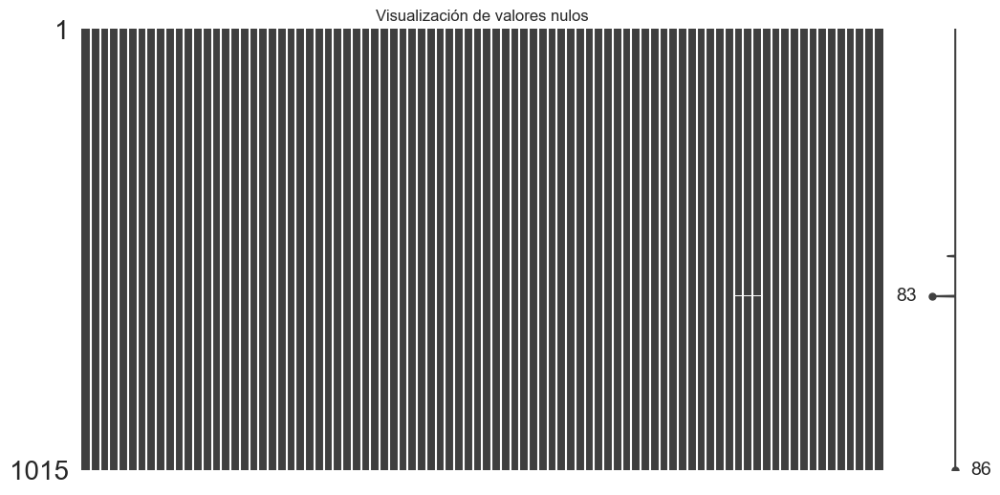

In [11]:
# Nulos
msno.matrix(df_final, figsize=(12,6))
plt.title("Visualización de valores nulos")
plt.show()

In [12]:
# Imputar nulos con la mediana en ambas columnas
df_final['color_avg_hue'].fillna(df_final['color_avg_hue'].median(), inplace=True)
df_final['color_avg_saturacion'].fillna(df_final['color_avg_saturacion'].median(), inplace=True)
df_final['color_avg_valor'].fillna(df_final['color_avg_valor'].median(), inplace=True)

# Verificar que no quedan nulos
print(df_final[['color_avg_hue', 'color_avg_saturacion', 'color_avg_valor']].isnull().sum())

color_avg_hue           0
color_avg_saturacion    0
color_avg_valor         0
dtype: int64


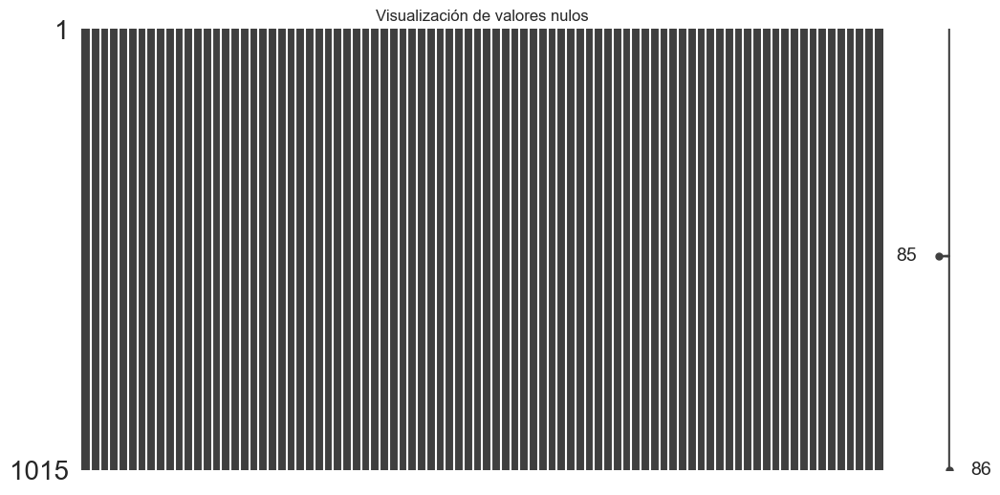

In [13]:
# Nulos
msno.matrix(df_final, figsize=(12,6))
plt.title("Visualización de valores nulos")
plt.show()

In [14]:
# tecnocasa_final libre de nulos
#df_final.to_parquet("../DATOS/tecnocasa_final.parquet", index=False)

In [15]:
# Separar tipos de variables
numericas = ['Precio', 'Dormitorios', 'Superficie', 'Num_baños', 'Año_de_construccion', 'Planta_ordinal',
             'Latitud', 'Longitud', 'Precio_m2', 'Longitud_desc', 'Riqueza_desc', 'Polaridad_desc', 
             'Subjetividad_desc', 'Adjetivos_positivos', 'Urgencia_desc', 'ruido_carretera', 'announcement_id',
             'dist_a_carretera', 'ruido_ferrocarril', 'ruido_urbano', 'dist_a_aglomeracion', 'ruido_aeropuerto', 'dist_a_aeropuerto', 'ruido_promedio', 
             'Renta_Neta_Media', 'nivel_lujo', 'nivel_modernidad', 'nivel_foto_profesional', 'equilibrio_composicion', 'num_imagenes',
             'color_avg_hue', 'color_avg_saturacion', 'color_avg_valor']

binarias = ['Metro', 'Renfe', 'Bus', 'Vistas', 'Garaje', 'Trastero', 'Piscina', 'Terraza_balcon', 'Seguridad_portero',
            'Amueblado', 'Calle_tranquila', 'Aire acondicionado', 'Calefaccion', 'Ascensor', 'Jardin', 'Hospital', 'Colegio', 'Supermercado',
            'Tienda', 'Restaurante', 'Bar', 'Farmacia', 'espacio_abierto']

categoricas = ['Estado_conservacion', 'Etiqueta', 'Tipo_de_inmueble', 'Tipo_vivienda', 'distrito/ciudad',
               'Localización_normalizada', 'Localizacion_Clave', 'tipo_suelo', 'material_pared', 'altura_techo', 'elementos_estructurales_visibles',
              'estilo_principal', 'calidad_iluminacion', 'distribucion_espacios', 'espacios_almacenaje', 'zonas_exteriores', 'tecnologia_visible', 'calidad_bano',
              'defectos_visibles', 'distorsion_perspectiva', 'color_principal']


### 3. Distribución de variables numéricas
Creamos histogramas para cada variable numérica para observar su distribución y posibles sesgos.

Visualizamos las correlaciones lineales entre variables numéricas, lo cual ayuda a detectar relaciones redundantes o dependencias.

Creamos boxplots para cada variable numérica con el objetivo de identificar valores atípicos.

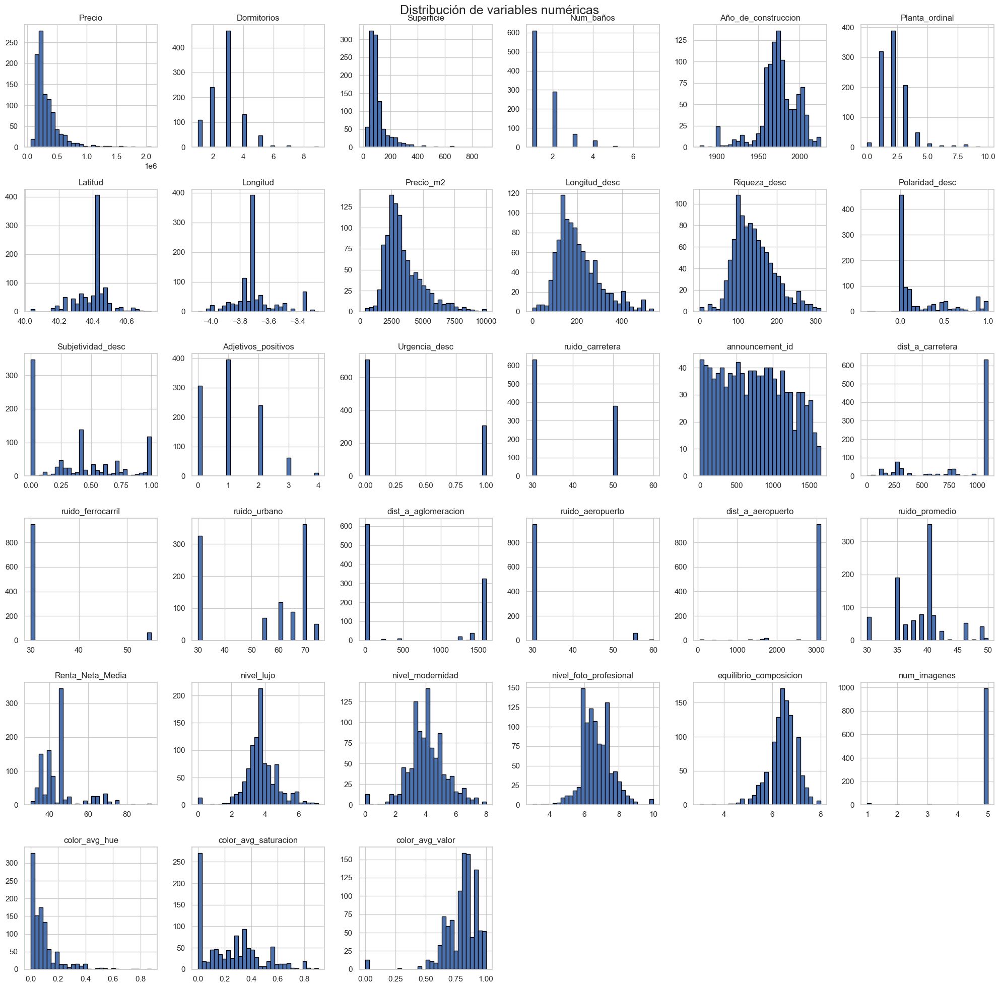

In [16]:
# Histogramas de variables numéricas
df_final[numericas].hist(figsize=(20, 20), bins=30, edgecolor='black')
plt.suptitle("Distribución de variables numéricas", fontsize=18)
plt.tight_layout()
plt.show()

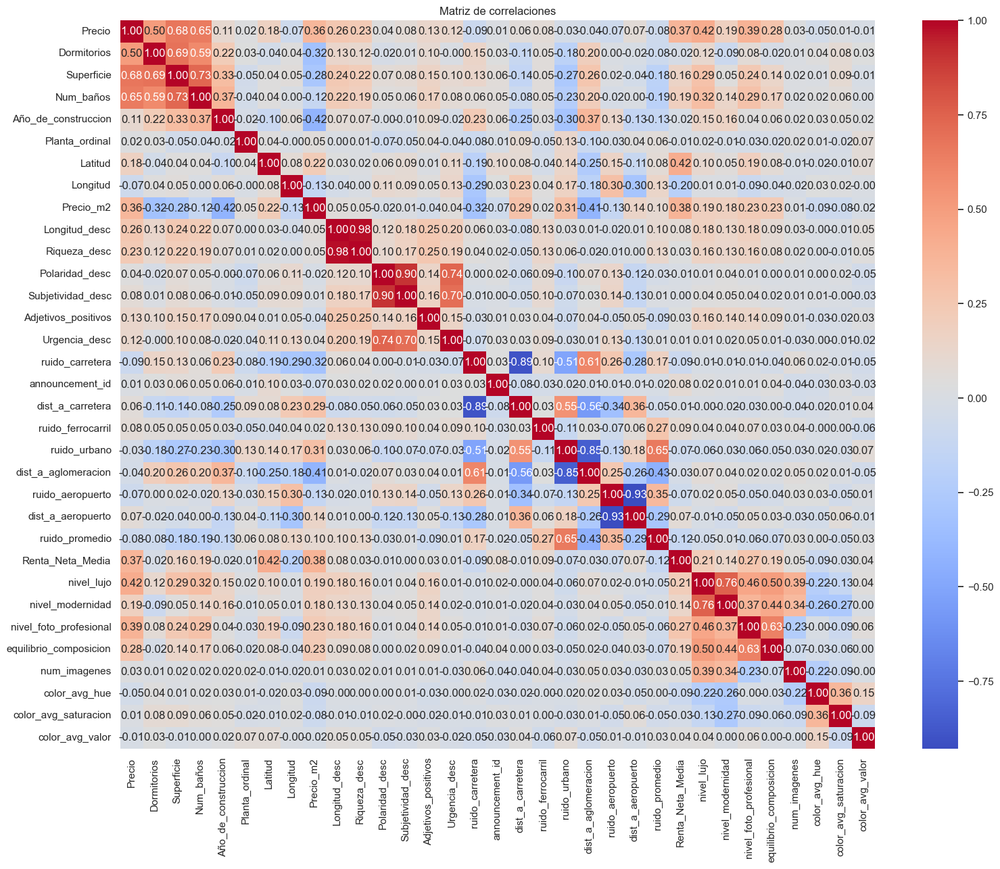

In [17]:
# Correlaciones
plt.figure(figsize=(18, 14))
sns.heatmap(df_final[numericas].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlaciones")
plt.show()

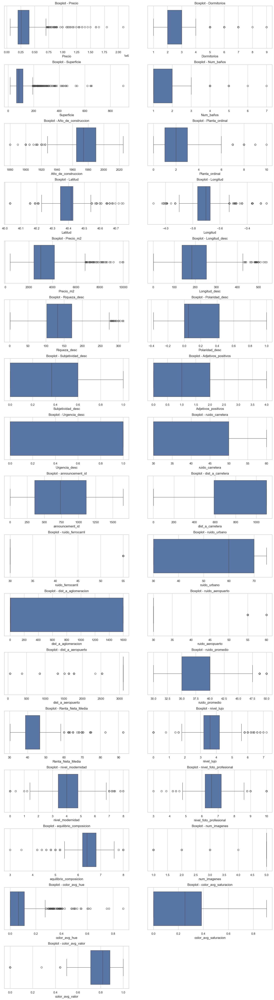

In [18]:
# Boxplots para detección de outliers
n_vars = len(numericas)
n_rows = (n_vars + 1) // 2

fig, axes = plt.subplots(n_rows, 2, figsize=(15, 3*n_rows))
fig.tight_layout(pad=3.0)
axes = axes.flatten()

for i, var in enumerate(numericas):
    sns.boxplot(data=df_final, x=var, ax=axes[i])
    axes[i].set_title(f"Boxplot - {var}")

if n_vars % 2 != 0:
    axes[-1].axis('off')

plt.show()

### 4. Distribución de variables binarias
Visualizamos cómo están distribuidas las variables binarias a través de histogramas.

Mostramos un resumen visual del número de veces que aparece el valor 1 en cada variable binaria.

Analizamos cómo varía el precio de los inmuebles en función de la presencia o ausencia de cada característica binaria.

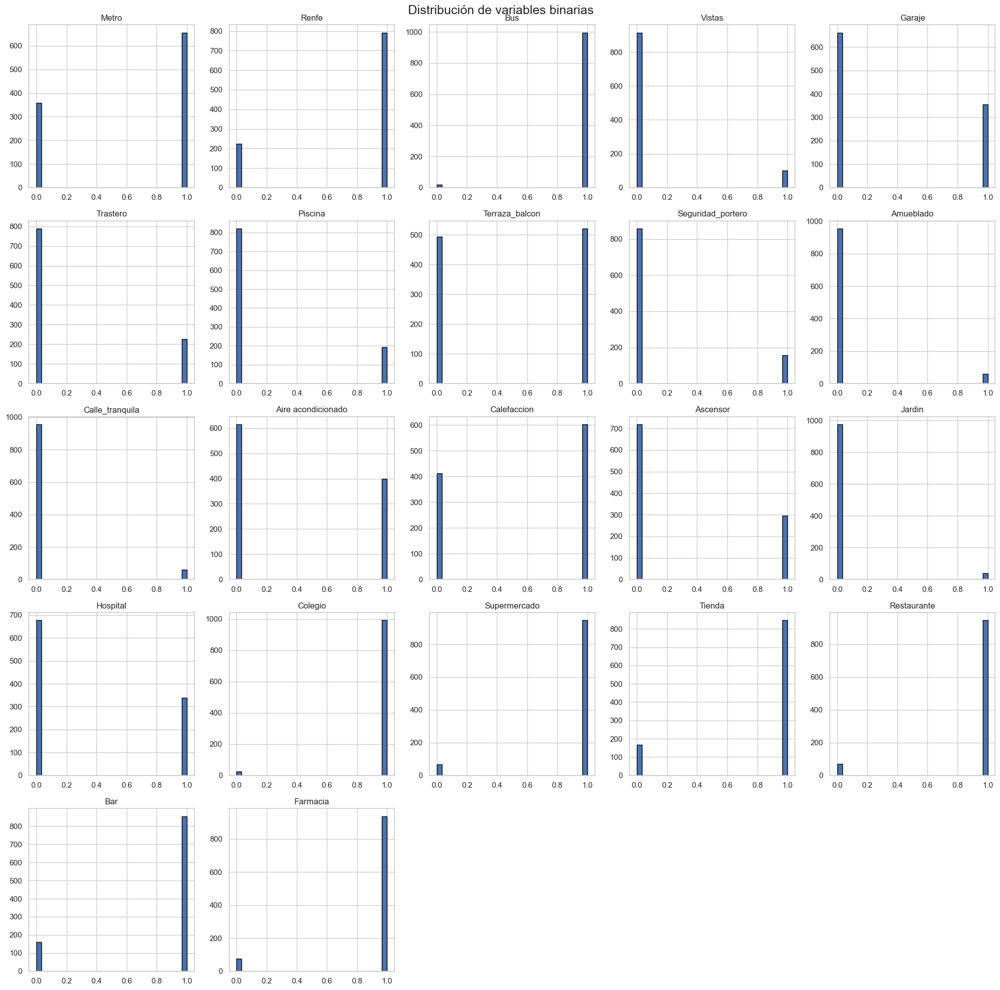

In [19]:
# Histogramas de variables binarias
df_final[binarias].hist(figsize=(20, 20), bins=30, edgecolor='black')
plt.suptitle("Distribución de variables binarias", fontsize=18)
plt.tight_layout()
plt.show()

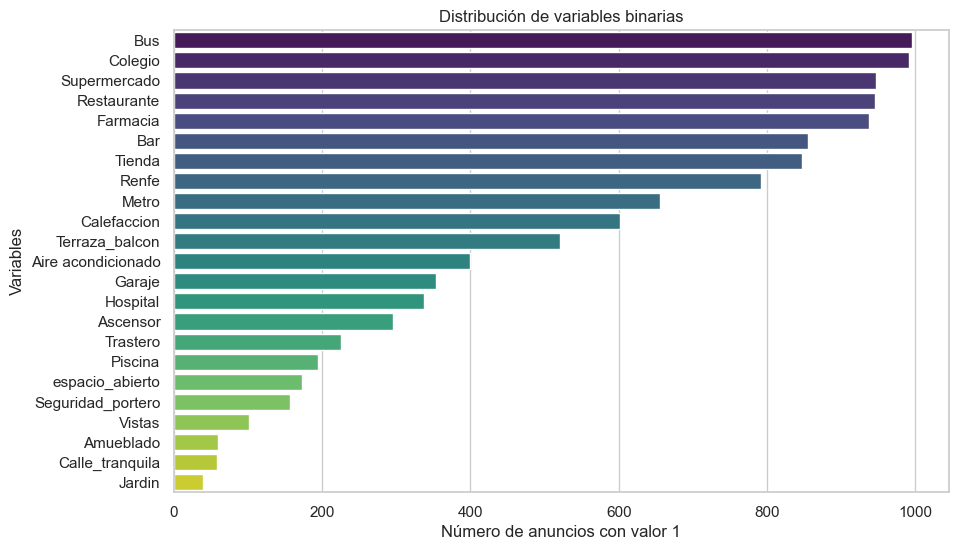

In [20]:
# Variables binarias: distribución
bin_summary = df_final[binarias].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=bin_summary.values, y=bin_summary.index, palette="viridis")
plt.title("Distribución de variables binarias")
plt.xlabel("Número de anuncios con valor 1")
plt.ylabel("Variables")
plt.show()

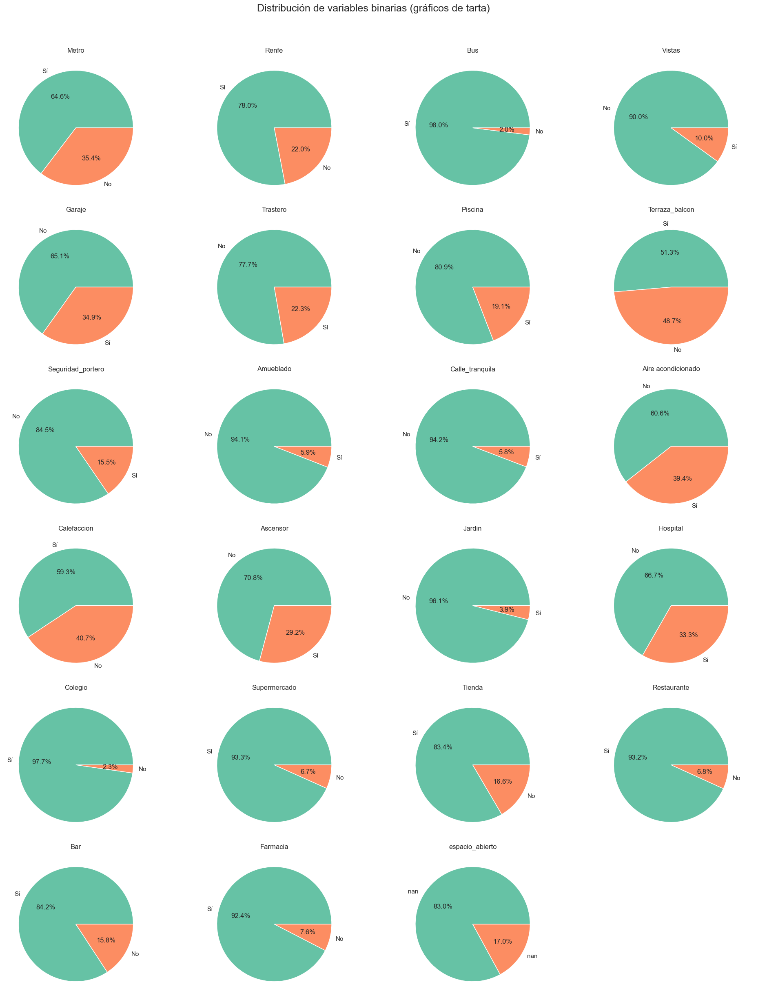

In [21]:
# Distribución de variables binarias (Gráficos de tarta)
cols = 4
rows = math.ceil(len(binarias) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(binarias):
    counts = df_final[col].value_counts()
    labels = counts.index.map({1: 'Sí', 0: 'No'})
    axes[i].pie(counts, labels=labels, autopct='%1.1f%%', colors=['#66c2a5', '#fc8d62'])
    axes[i].set_title(col)

# Ocultar ejes vacíos
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle("Distribución de variables binarias (gráficos de tarta)", fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

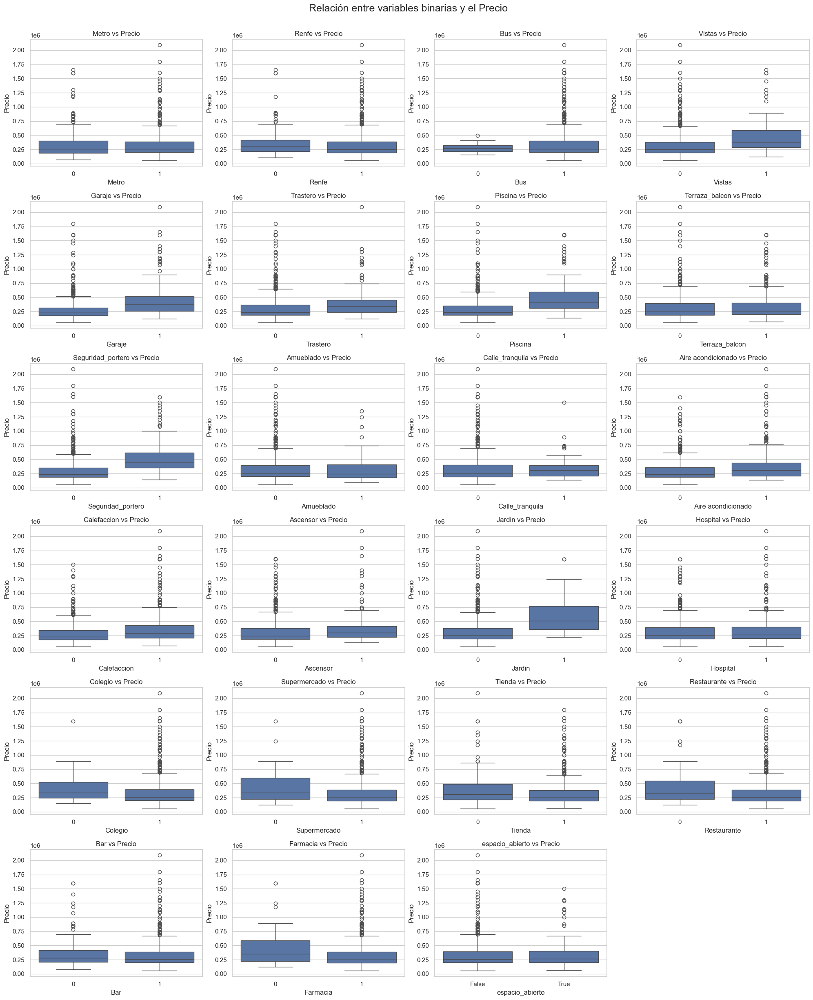

In [22]:
# Relación con Precio
cols = 4
rows = math.ceil(len(binarias) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(binarias):
    sns.boxplot(x=col, y='Precio', data=df_final, ax=axes[i])
    axes[i].set_title(f'{col} vs Precio')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle("Relación entre variables binarias y el Precio", fontsize=18, y=1.02)
plt.show()

### 5. Visualización de imágenes del anuncio
Mostramos una selección de imágenes asociadas al primer anuncio del dataset. Esto permite inspeccionar visualmente el tipo y calidad de las imágenes incluidas, lo cual es útil para entender las variables relacionadas con visión computacional o para evaluación cualitativa.


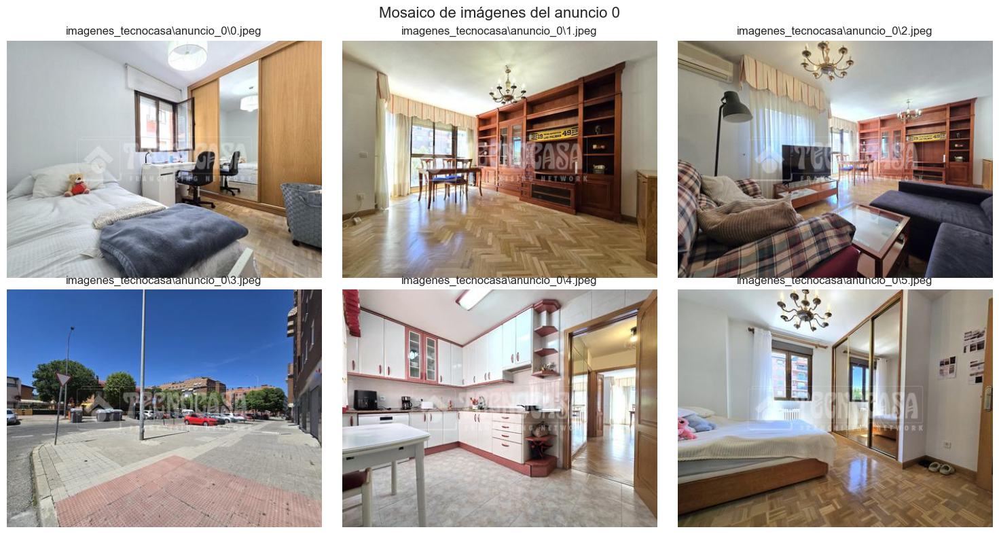

In [23]:
from PIL import Image

ruta_imagenes = df_final.loc[0, 'Imagenes_locales']
primera_ruta = ruta_imagenes[0]

fig, axs = plt.subplots(2, 3, figsize=(15, 8))

for i, ax in enumerate(axs.flatten()):
    if i < len(ruta_imagenes):
        img = Image.open(ruta_imagenes[i])
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"{ruta_imagenes[i].split('/')[-1]}")
    else:
        ax.axis('off')

plt.suptitle("Mosaico de imágenes del anuncio 0", fontsize=16)
plt.tight_layout()
plt.show()

Estudiamos el vínculo entre variables extraídas de las imágenes de los anuncios y el precio de los inmuebles.

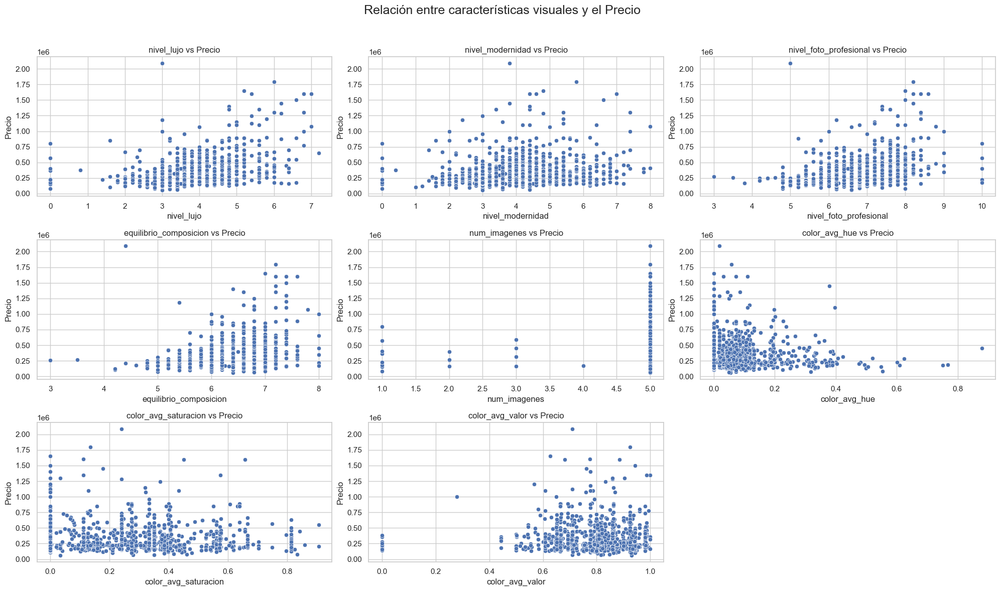

In [24]:
# Lista de variables relacionadas con las imágenes
imagen_vars = ['nivel_lujo', 'nivel_modernidad', 'nivel_foto_profesional',
               'equilibrio_composicion', 'num_imagenes',
               'color_avg_hue', 'color_avg_saturacion', 'color_avg_valor']


n = len(imagen_vars)
rows = (n + 2) // 3

fig, axs = plt.subplots(rows, 3, figsize=(20, rows * 4))
fig.suptitle("Relación entre características visuales y el Precio", fontsize=18)

axs = axs.flatten()

for i, col in enumerate(imagen_vars):
    sns.scatterplot(data=df_final, x=col, y='Precio', ax=axs[i])
    axs[i].set_title(f"{col} vs Precio")
    
for j in range(i + 1, len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 6. Frecuencia de categorías en variables categóricas
Mostramos cuántas veces aparece cada categoría en cada una de las variables categóricas.


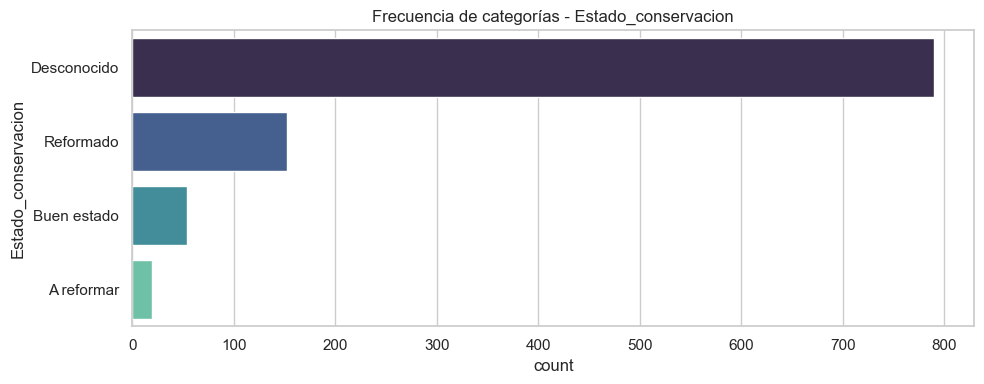

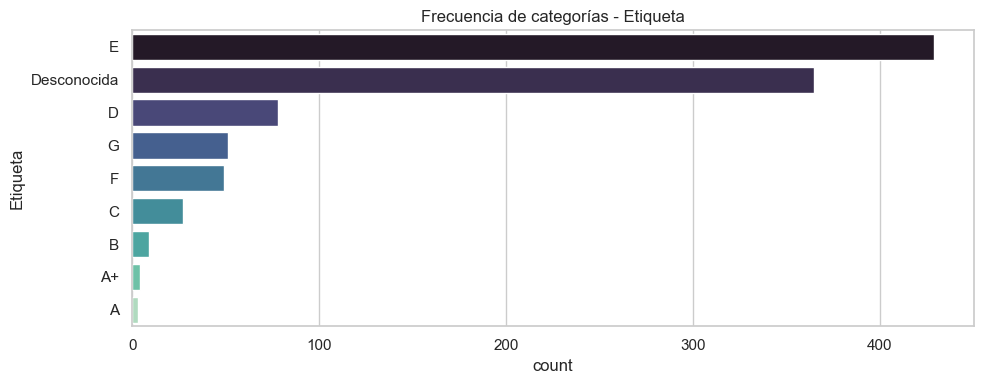

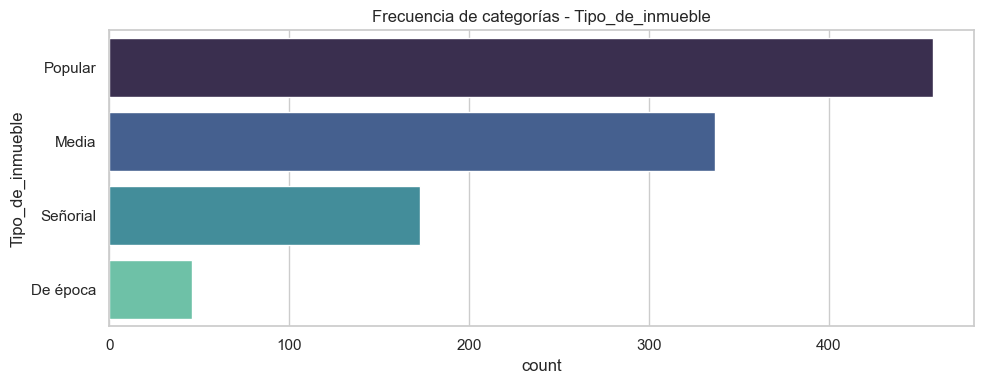

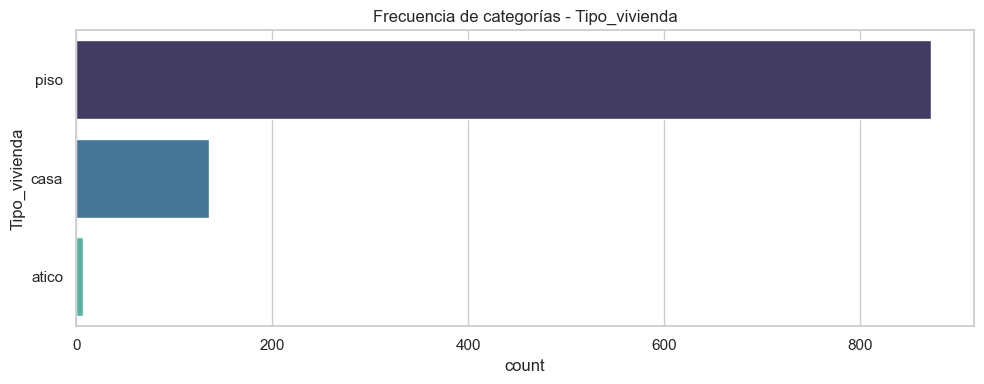

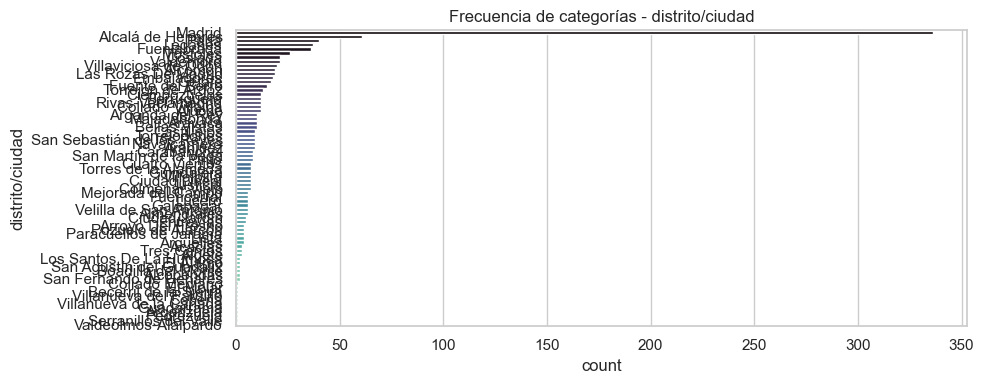

...

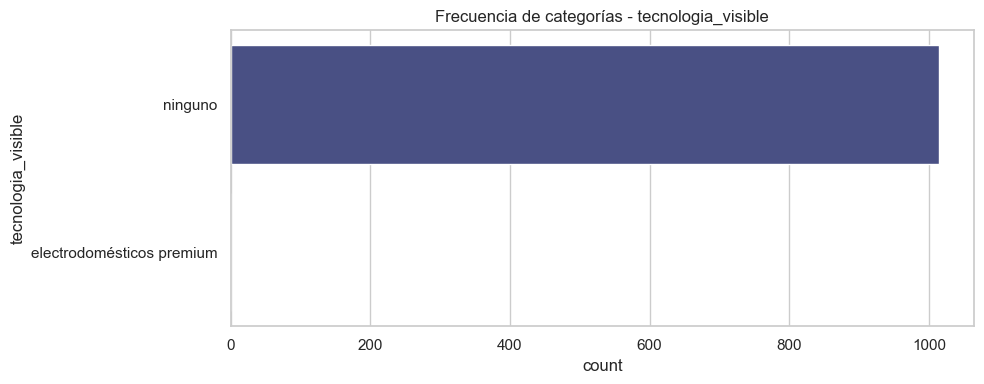

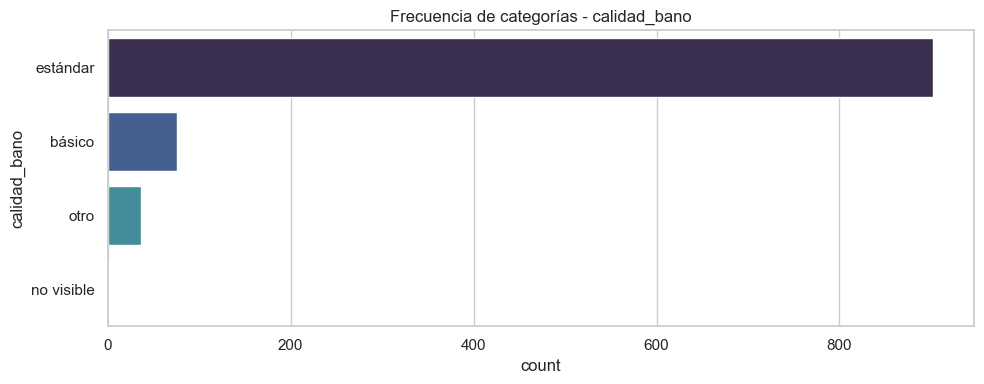

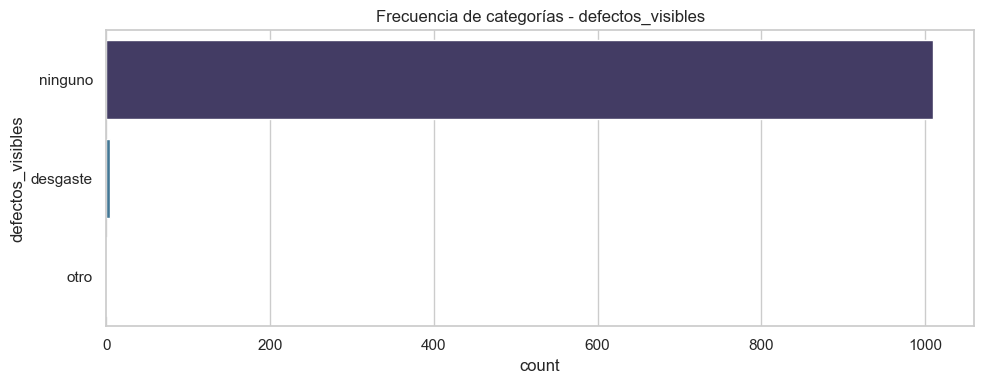

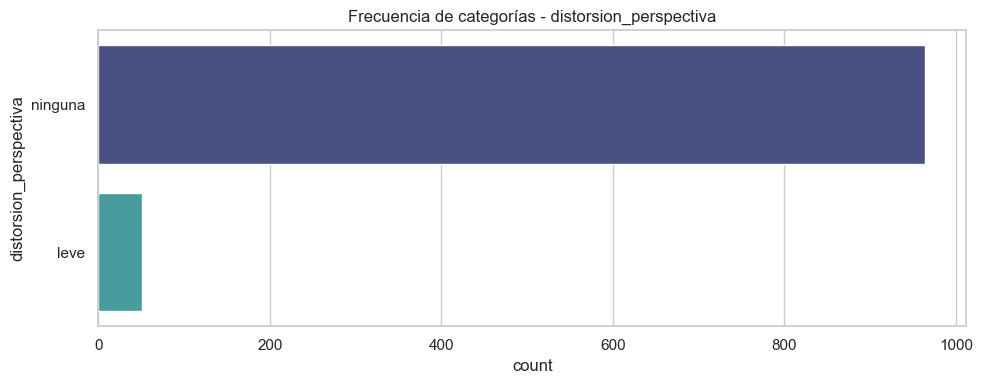

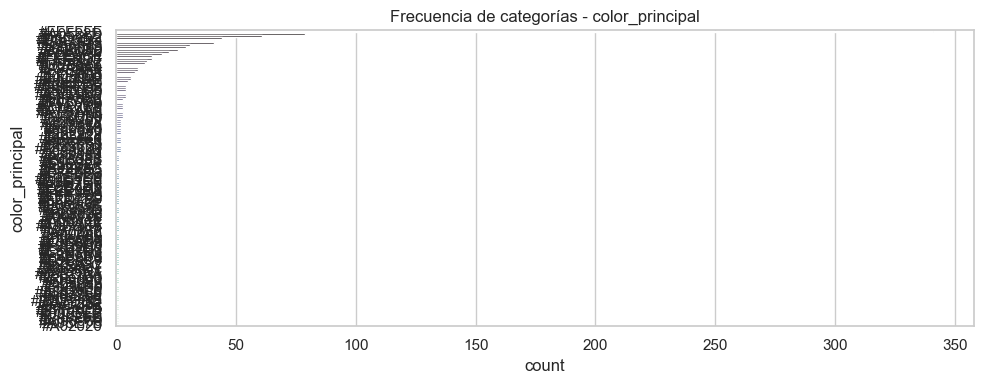

In [29]:
# Variables categóricas: conteos
for col in categoricas:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df_final, y=col, order=df_final[col].value_counts().index, palette="mako")
    plt.title(f"Frecuencia de categorías - {col}")
    plt.tight_layout()
    plt.show()

### 7. Relación entre Superficie y Precio
Utilizamos un scatterplot interactivo para visualizar la relación entre superficie y precio, diferenciando por tipo de inmueble.


In [30]:
# Precio vs Superficie (scatter interactivo)
import plotly.express as px
import plotly.io as pio

pio.renderers.default = 'notebook'

fig = px.scatter(df_final, x="Superficie", y="Precio", color="Tipo_de_inmueble",
                 hover_data=["Dormitorios", "Num_baños", "distrito/ciudad"],
                 title="Precio vs Superficie por tipo de inmueble")
fig.show()

### 8. Distribución del Precio por m² según distrito
Comparamos los precios por metro cuadrado entre los distintos distritos usando boxplots ordenados por mediana.


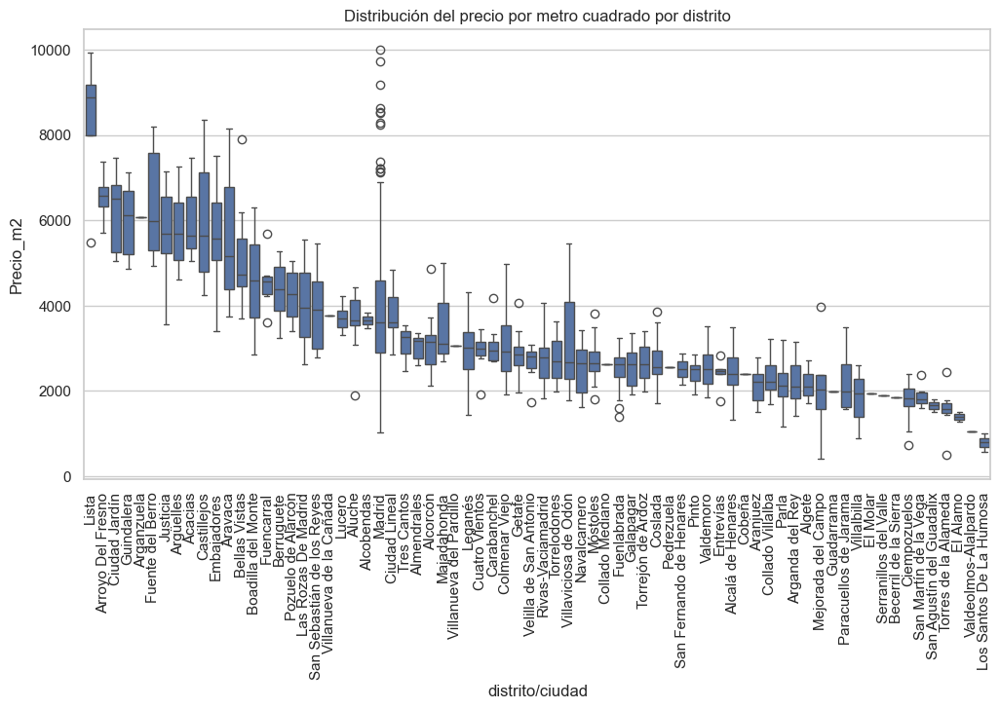

In [31]:
# Precio_m2 por distrito
plt.figure(figsize=(12, 6))
order = df_final.groupby("distrito/ciudad")["Precio_m2"].median().sort_values(ascending=False).index
sns.boxplot(data=df_final, x="distrito/ciudad", y="Precio_m2", order=order)
plt.xticks(rotation=90)
plt.title("Distribución del precio por metro cuadrado por distrito")
plt.show()

### 9. Mapa geográfico con precios
Visualizamos en un mapa la localización de los inmuebles, utilizando el precio como escala de color y superficie como tamaño.


In [33]:
# Mapa con ubicación geográfica
fig = px.scatter_mapbox(df_final, lat="Latitud", lon="Longitud", color="Precio",
                        hover_name="Localización_normalizada", size="Superficie",
                        color_continuous_scale=px.colors.sequential.Viridis,
                        mapbox_style="carto-positron", zoom=10)
fig.update_layout(title="Distribución geográfica de inmuebles")
fig.show()

### 10. Variables NLP
Estudiamos cómo se relacionan variables derivadas de las descripciones textuales con el precio de los inmuebles.

Mostramos una matriz de correlación para ver cómo se relacionan entre sí las variables extraídas del texto.

Analizamos la interacción entre polaridad, subjetividad, número de adjetivos y precio usando un gráfico interactivo.


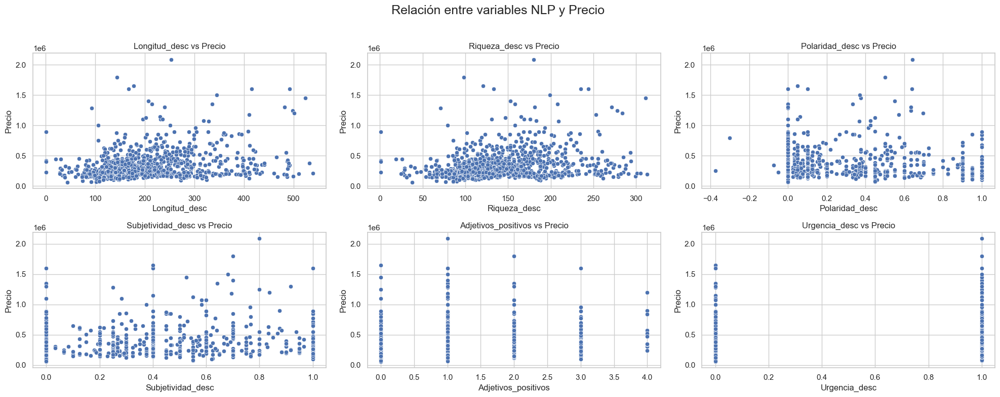

In [34]:
nlp_vars = ['Longitud_desc', 'Riqueza_desc', 'Polaridad_desc',
            'Subjetividad_desc', 'Adjetivos_positivos', 'Urgencia_desc']

n = len(nlp_vars)
rows = (n + 2) // 3 
fig, axs = plt.subplots(rows, 3, figsize=(20, rows * 4))
fig.suptitle("Relación entre variables NLP y Precio", fontsize=18)
axs = axs.flatten()

for i, col in enumerate(nlp_vars):
    sns.scatterplot(data=df_final, x=col, y='Precio', ax=axs[i])
    axs[i].set_title(f"{col} vs Precio")

for j in range(i + 1, len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

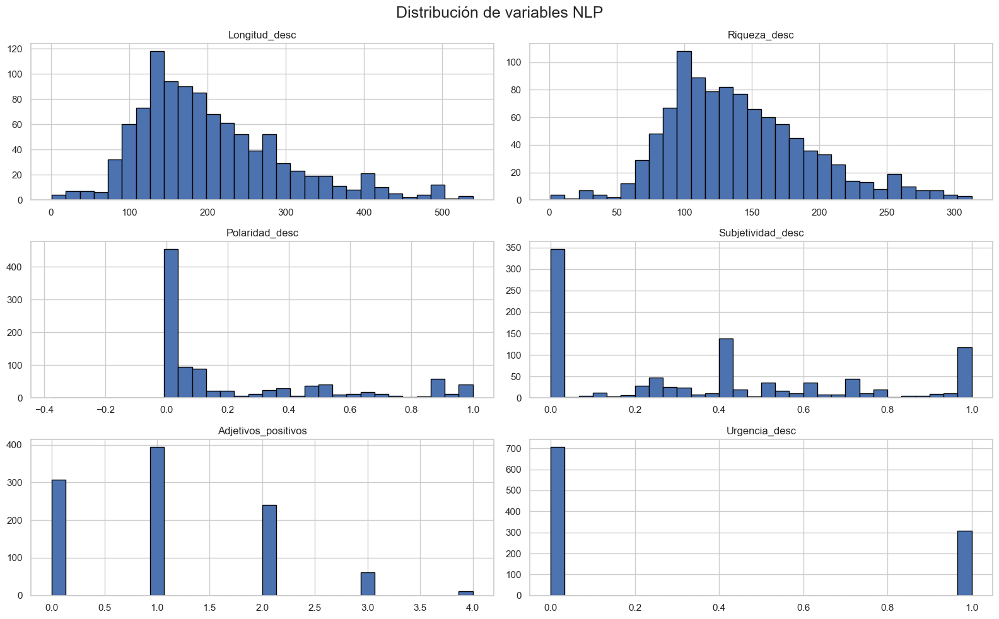

In [35]:
df_final[nlp_vars].hist(figsize=(16, 10), bins=30, edgecolor='black')
plt.suptitle("Distribución de variables NLP", fontsize=18)
plt.tight_layout()
plt.show()

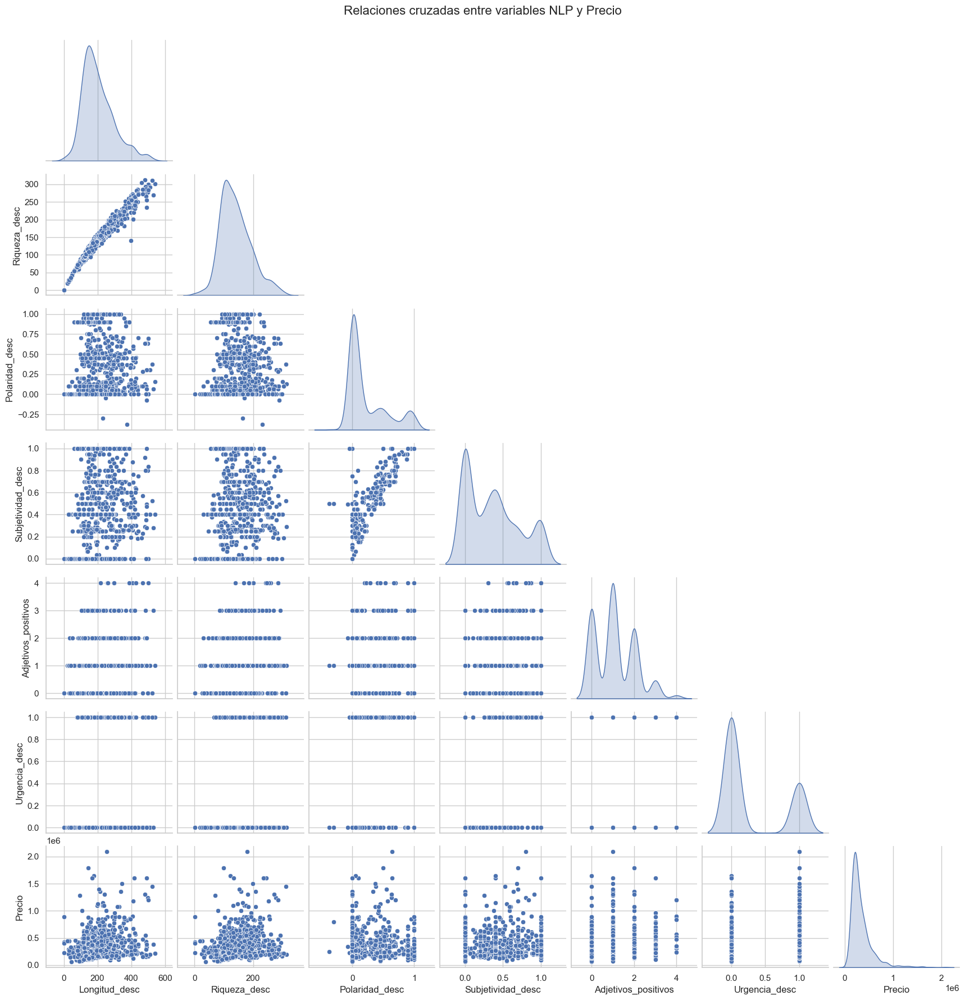

In [36]:
sns.pairplot(df_final[nlp_vars + ['Precio']], corner=True, diag_kind='kde')
plt.suptitle("Relaciones cruzadas entre variables NLP y Precio", y=1.02, fontsize=16)
plt.show()

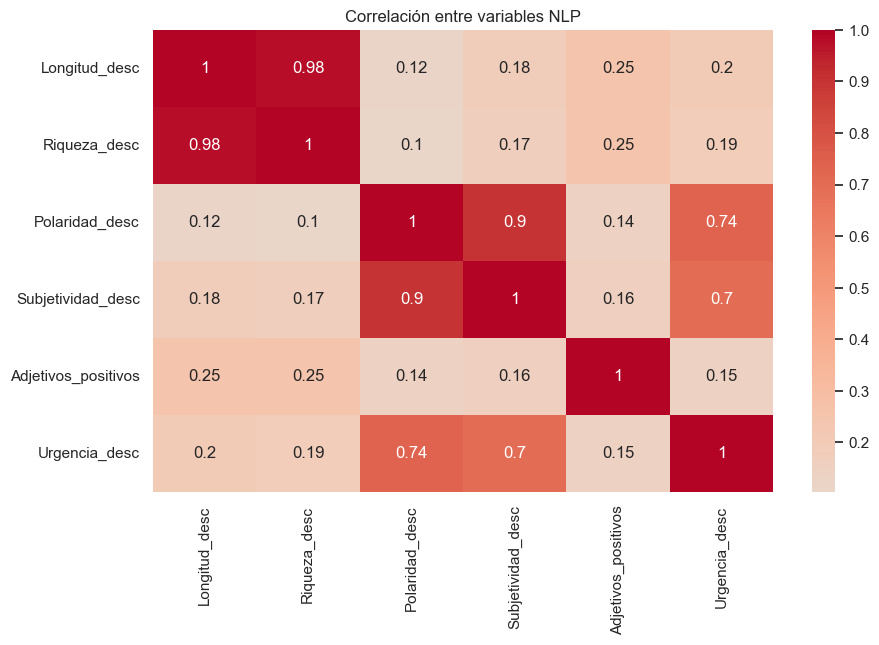

In [37]:
plt.figure(figsize=(10, 6))
corr = df_final[nlp_vars].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title("Correlación entre variables NLP")
plt.show()

In [38]:
import plotly.express as px

fig = px.scatter(df_final, 
                 x='Polaridad_desc', 
                 y='Subjetividad_desc', 
                 color='Precio',
                 size='Adjetivos_positivos',
                 hover_data=['Longitud_desc', 'Riqueza_desc'],
                 title='Sentimiento y subjetividad en la descripción vs Precio')
fig.show()

### 11. Relación entre los niveles de ruido ambiental y el precio
Los niveles de ruido (carretera, ferrocarril, urbano, aeropuerto, promedio) pueden influir significativamente en el valor de una propiedad. A continuación se visualiza la relación entre estos tipos de ruido y el precio de los inmuebles.

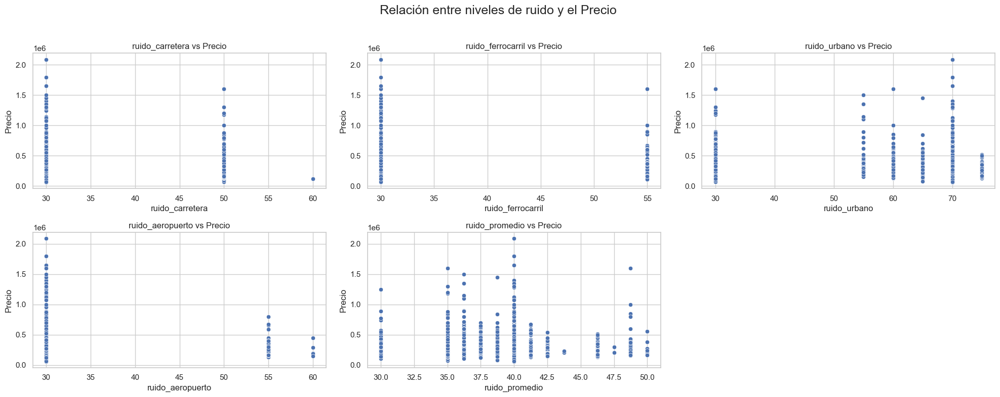

In [39]:
ruido_vars = ['ruido_carretera', 'ruido_ferrocarril', 'ruido_urbano', 'ruido_aeropuerto', 'ruido_promedio']

n = len(ruido_vars)
rows = (n + 2) // 3

fig, axs = plt.subplots(rows, 3, figsize=(20, rows * 4))
fig.suptitle("Relación entre niveles de ruido y el Precio", fontsize=18)
axs = axs.flatten()

for i, col in enumerate(ruido_vars):
    sns.scatterplot(data=df_final, x=col, y='Precio', ax=axs[i])
    axs[i].set_title(f"{col} vs Precio")

# Eliminar ejes vacíos si los hay
for j in range(i + 1, len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 12. Distribución de la renta neta media por distrito
Analizar la renta media de las zonas es crucial para entender el contexto socioeconómico de los inmuebles. A continuación se presenta la distribución de la renta neta media en función del distrito.

Se analiza cómo varía el precio de los inmuebles en función de la renta neta media de la zona. Esto permite evaluar si los precios están alineados con el poder adquisitivo local.


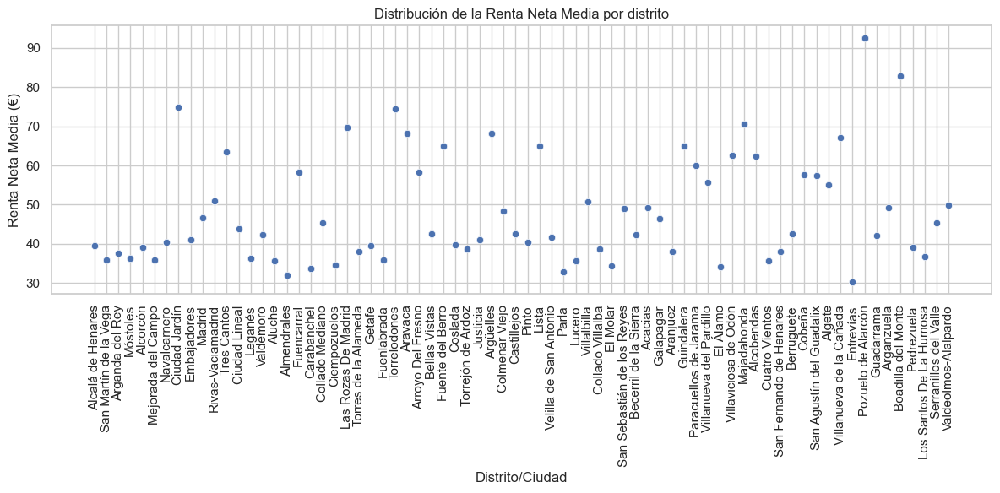

In [40]:
plt.figure(figsize=(12, 6))
order = df_final.groupby("distrito/ciudad")["Renta_Neta_Media"].median().sort_values(ascending=False).index
sns.scatterplot(data=df_final, x="distrito/ciudad", y="Renta_Neta_Media")
plt.xticks(rotation=90)
plt.title("Distribución de la Renta Neta Media por distrito")
plt.xlabel("Distrito/Ciudad")
plt.ylabel("Renta Neta Media (€)")
plt.tight_layout()
plt.show()

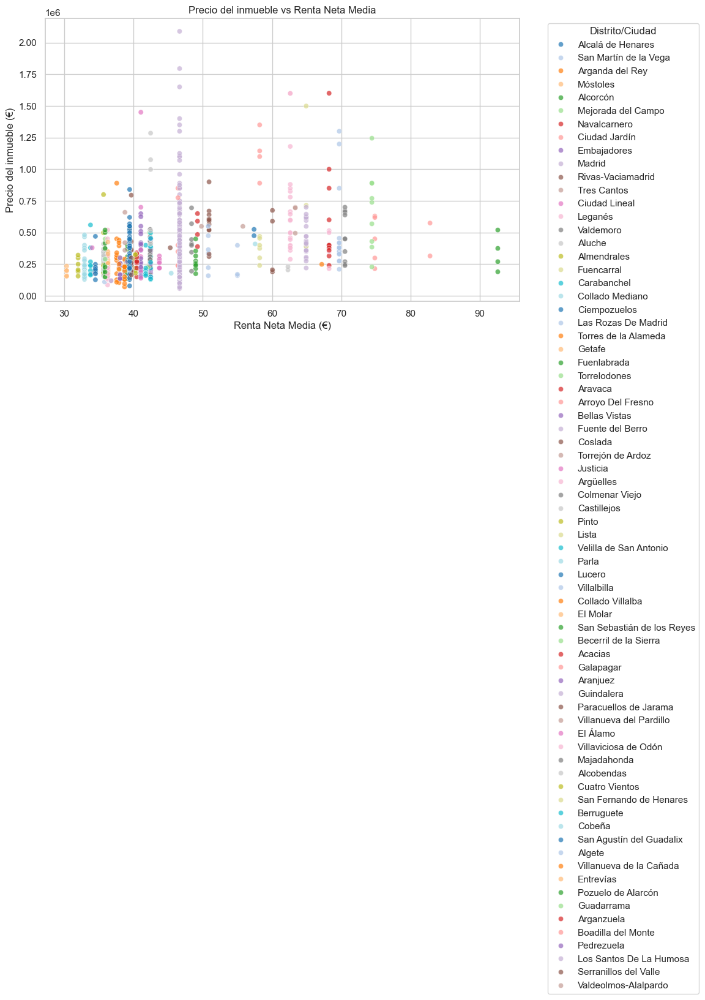

In [41]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_final, x='Renta_Neta_Media', y='Precio', hue='distrito/ciudad', palette='tab20', alpha=0.7)
plt.title("Precio del inmueble vs Renta Neta Media")
plt.xlabel("Renta Neta Media (€)")
plt.ylabel("Precio del inmueble (€)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Distrito/Ciudad')
plt.tight_layout()
plt.show()

### 13. Reducción de dimensionalidad con PCA
Aplicamos PCA a las variables numéricas para representar la información en 2 dimensiones y observar la distribución según el precio.


In [42]:
# Análisis Multivariable Avanzado (PCA / t-SNE para variables numéricas)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(df_final[numericas].dropna())
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(pca_result, columns=['PC1', 'PC2'])
df_pca['Precio'] = df_final['Precio'].dropna().values[:len(df_pca)]

px.scatter(df_pca, x='PC1', y='PC2', color='Precio', title="PCA de variables numéricas coloreado por Precio")